In [ ]:
import pandas as pd
import numpy as np
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings

warnings.filterwarnings('ignore')

In [3]:
# ==============================================================================
# 1. LOAD AND MERGE DATA (CHAMPION DATASET)
# ==============================================================================
print("Loading Champion Dataset (Top 200) and HMM Features...")

# Load Top 200 (Baseline to beat: 0.7713)
X_top200 = pd.read_parquet('../data/processed/features_top200.parquet')

# Load the 6 HMM variables
X_hmm = pd.read_parquet('../data/processed/features_hmm.parquet')

# Merge both dataframes using the index ('id')
X_combined = X_top200.join(X_hmm)

# Handle the Categorical feature for all 3 models
if 'Cluster_ID' in X_combined.columns:
    print("One-Hot Encoding 'Cluster_ID' to prevent CatBoost/Sklearn conflicts...")
    X_combined = pd.get_dummies(X_combined, columns=['Cluster_ID']) * 1

X_combined.columns = X_combined.columns.str.replace(r'[^\w\s]', '_', regex=True)

# Load Target
y_train = pd.read_parquet('../data/raw/y_train.parquet')
y = y_train.loc[X_combined.index]['structural_breakpoint']

print(f"Combined Features shape: {X_combined.shape}")

# Calculate Class Imbalance Ratio
imbalance_ratio = float((y == 0).sum() / (y == 1).sum())
print(f"Class imbalance ratio (False/True): {imbalance_ratio:.4f}")

Loading Champion Dataset (Top 200) and HMM Features...
One-Hot Encoding 'Cluster_ID' to prevent CatBoost/Sklearn conflicts...
Combined Features shape: (10001, 213)
Class imbalance ratio (False/True): 2.4380


In [4]:
# ==============================================================================
# 2. DEFINE THE ENSEMBLE (THE COUNCIL OF WISE MODELS)
# ==============================================================================

# --- 1. XGBoost ---
# Level-wise tree growth. Robust and reliable.
xgb_model = xgb.XGBClassifier(
    n_estimators=300, 
    learning_rate=0.05, 
    max_depth=6, 
    subsample=0.8, 
    colsample_bytree=0.8, 
    scale_pos_weight=imbalance_ratio, 
    eval_metric='auc', 
    random_state=42, 
    n_jobs=-1,
    enable_categorical=True # Crucial for 'Cluster_ID'
)

# --- 2. LightGBM ---
# Leaf-wise tree growth. Fantastic at finding subtle splits, very fast.
lgb_model = lgb.LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    num_leaves=31, # Specific to LightGBM leaf-wise growth
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=imbalance_ratio,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

# --- 3. CatBoost ---
# Oblivious trees. The absolute king of handling categorical variables.
# Note: CatBoost handles imbalance using scale_pos_weight as well.
cat_model = CatBoostClassifier(
    iterations=300,
    learning_rate=0.05,
    depth=6,
    scale_pos_weight=imbalance_ratio,
    eval_metric='AUC',
    random_state=42,
    verbose=0, # Keep console clean during CV
    thread_count=-1
)

# --- THE ENSEMBLE (Soft Voting) ---
# 'soft' means it averages the predicted probabilities from the 3 models
# instead of just doing a majority vote of hard labels.
ensemble_model = VotingClassifier(
    estimators=[
        ('xgb', xgb_model),
        ('lgb', lgb_model),
        ('cat', cat_model)
    ],
    voting='soft',
    n_jobs=1 # Set to 1 because the underlying models already use all cores
)

In [19]:
# ==============================================================================
# 3. EVALUATE ENSEMBLE (5-FOLD CV)
# ==============================================================================
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("\n" + "="*60)
print("EVALUATING ENSEMBLE: XGB + LGBM + CATBOOST")
print("Target to beat: 0.7713 (Single XGBoost)")
print("="*60)

# Calculate ROC AUC
# Note: Cross-validating an ensemble takes ~3x longer than a single model
scores_auc = cross_val_score(ensemble_model, X_combined, y, cv=cv_strategy, scoring='roc_auc', n_jobs=1)
mean_auc = np.mean(scores_auc)
std_auc = np.std(scores_auc)

print(f"\nEnsemble Mean ROC AUC: {mean_auc:.4f} (+/- {std_auc:.4f})")

# Generate cross-validated predictions for classification report
# method='predict_proba' ensures we use the soft voting output
y_pred_proba_cv = cross_val_predict(ensemble_model, X_combined, y, cv=cv_strategy, method='predict_proba', n_jobs=1)[:, 1]

# Convert probabilities back to binary labels using standard 0.5 threshold
y_pred_cv = (y_pred_proba_cv >= 0.5).astype(int)

print("\nCLASSIFICATION REPORT:")
print(classification_report(y, y_pred_cv, digits=4))


EVALUATING ENSEMBLE: XGB + LGBM + CATBOOST
Target to beat: 0.7713 (Single XGBoost)

Ensemble Mean ROC AUC: 0.7829 (+/- 0.0058)

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

       False     0.8199    0.8852    0.8513      7092
        True     0.6527    0.5260    0.5825      2909

    accuracy                         0.7807     10001
   macro avg     0.7363    0.7056    0.7169     10001
weighted avg     0.7713    0.7807    0.7731     10001



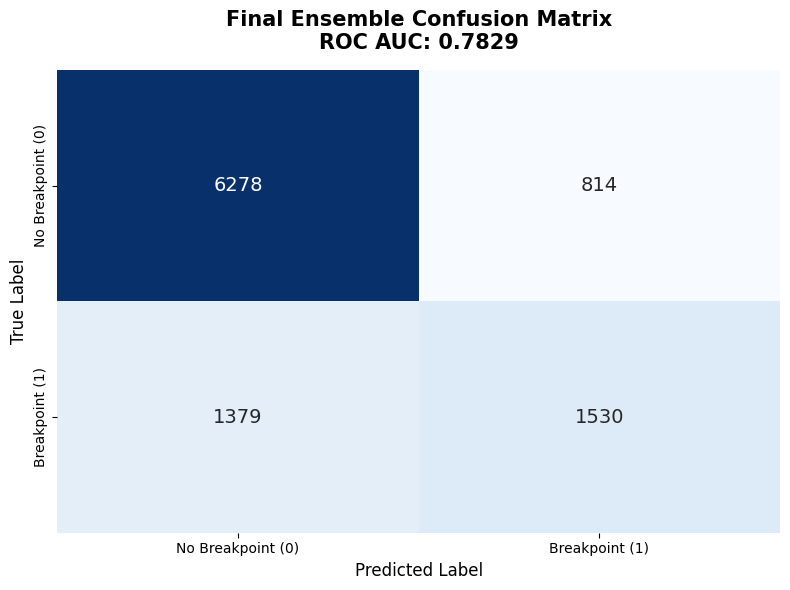

In [20]:
# ==============================================================================
# 4. CONFUSION MATRIX VISUALIZATION
# ==============================================================================
cm = confusion_matrix(y, y_pred_cv)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['No Breakpoint (0)', 'Breakpoint (1)'],
            yticklabels=['No Breakpoint (0)', 'Breakpoint (1)'],
            annot_kws={"size": 14})

plt.title(f'Final Ensemble Confusion Matrix\nROC AUC: {mean_auc:.4f}', 
          fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()